# EfficientNetB0 + Coordinate Attention (CA) + noresc — thêm augmentation nhẹ và early stopping

## Thay đổi so với notebook `efficientnetb0-ca-noresc`
1. **Augmentation nhẹ, chỉ cho tập train** (`USE_AUGMENTATION`): xoay ±10°, dịch ±5%, zoom 0.9–1.1, độ sáng 0.9–1.1; **không lật ngang**. Valid và test giữ nguyên ảnh gốc.
2. **Early stopping theo val_auc** (`USE_EARLY_STOP`): dừng khi `val_auc` không cải thiện (quá `ES_MIN_DELTA_AUC`) trong `ES_PATIENCE = 5` epoch liên tiếp.

Mọi thứ khác giữ nguyên (khối CA, `INPUT_RESCALE = None`, split theo bệnh nhân, Adam lr 1e-3, `ReduceLROnPlateau(val_loss)`, tối đa 20 epoch, batch 32, ngưỡng F1, chọn checkpoint `val_auc`, `SEED = 2018` và `enable_op_determinism`), nên chênh lệch kết quả phản ánh tác động của hai thay đổi này. Muốn tách riêng từng tác động, chạy một lần với `USE_AUGMENTATION = False` (chỉ có early stopping) rồi một lần bật cả hai.

## Lý do
**Augmentation.** Sau khi bỏ rescale kép, huấn luyện ổn định hơn nhưng mô hình bắt đầu overfit sớm: ở lần chạy noresc trước (không đặt seed, 20 epoch), train loss giảm liên tục từ 0.143 xuống khoảng 0.089 trong khi val_loss chạm đáy 0.131 ở epoch 3 rồi tăng lên khoảng 0.148 và val AUC đạt đỉnh 0.798 ở epoch 2 rồi tụt về khoảng 0.786. Augmentation làm ảnh train đa dạng hơn ở mỗi epoch để giảm việc ghi nhớ ảnh train. Cần phân biệt rõ: augmentation nhằm **giảm overfitting**; nó không giải quyết mất cân bằng lớp (nhiều bệnh hiếm như Hernia, Pneumonia, Fibrosis), vấn đề đó cần cách khác (trọng số lớp, lấy mẫu lại).
- Các phép biến đổi được chọn nhẹ và thuộc loại hình học/độ sáng vốn xảy ra khi chụp X-quang (tư thế, khoảng cách, phơi sáng). **Không lật ngang** vì vị trí tim và các cơ quan mang thông tin giải phẫu; có thể bật bằng `AUG_HFLIP` nếu muốn thử.
- Ô kiểm tra bằng mắt ngay sau bước tạo generator in hàng ảnh gốc và hàng ảnh đã augment để chắc rằng chúng vẫn là X-quang bình thường.

**Early stopping.** Sau những epoch đầu, val_auc gần như đứng yên trong khi `ReduceLROnPlateau` hạ dần learning rate; các epoch sau không đổi kết quả mà vẫn tốn thời gian GPU. Dừng sau 5 epoch val_auc không tiến bộ rút ngắn thời gian chạy mà **không đổi checkpoint được chọn**, vì trọng số của epoch val_auc tốt nhất đã được lưu riêng (không khôi phục trọng số khi dừng). Patience 5 để `ReduceLROnPlateau` (patience 2 theo val_loss) kịp hạ lr và cho mô hình vài epoch thử lại trước khi dừng.

## Lưu ý
- Augmentation chạy trên CPU nên mỗi epoch có thể lâu hơn bản trước; early stopping bù lại một phần.
- Kết quả là của MỘT seed; chênh lệch nhỏ (cỡ ±0.01 AUC trung bình) chưa đủ để kết luận. Nên đọc cả đường cong huấn luyện (khoảng cách giữa train loss và val loss).

## Khối CA, split và đánh giá
CA (Hou et al., 2021: `reduction=32`, h-swish) chèn sau backbone (7×7×1280) → Global Average Pooling → Dense sigmoid 14 lớp. Split: test = `test_list.txt` chính thức của NIH; `train_val_list.txt` chia 80/20 theo `Patient ID` (`GroupShuffleSplit`, `random_state=2018`). Ngưỡng từng bệnh tối ưu theo `THRESHOLD_CRITERION = 'f1'`, chọn trên validation rồi áp lên test.

## So sánh
Cell cuối so sánh bốn bản theo thứ tự cải tiến: **benchmark (B0)** → **B0 + CA (1/255)** → **B0 + CA noresc** → **bản này (noresc + augmentation + early stopping)**. So sánh có kiểm soát cho riêng bước này là với bản noresc ngay trước nó. Số của ba bản trước được ghi cố định trong cell đó (sáu dict `BENCH_*`, `CA_*`, `NORESC_*`); chỉ cần dán số mới khi có kết quả.

In [1]:
# [KAGGLE] Dùng Keras 2 (tf_keras) để chạy đúng API Keras 2 của notebook gốc.
# Biến môi trường này PHẢI đặt trước khi import tensorflow.
import os, sys, subprocess, importlib.metadata as _md
os.environ["TF_USE_LEGACY_KERAS"] = "1"
if "tensorflow" in sys.modules:
    print("CẢNH BÁO: tensorflow đã được import trước cell này -> Restart session rồi chạy lại từ cell đầu.")
try:
    import tf_keras
except ImportError:
    _tfv = ".".join(_md.version("tensorflow").split(".")[:2])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"tf_keras~={_tfv}.0"])
    import tf_keras
print("tensorflow", _md.version("tensorflow"), "| tf_keras", _md.version("tf_keras"))

tensorflow 2.20.0 | tf_keras 2.20.1


In [2]:
import math, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
print(tf.__version__, tf.keras.Model.__module__)
assert tf.keras.Model.__module__.startswith("tf_keras"), "tf.keras không phải Keras 2 -> kiểm tra TF_USE_LEGACY_KERAS / tf_keras"

2.20.0 tf_keras.src.engine.training


In [3]:
import random
SEED = 2018
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()   # bắt các phép GPU cho kết quả lặp lại được
print('SEED =', SEED, '| op determinism bật')

SEED = 2018 | op determinism bật


In [4]:
# =====================================================================
#                      CẤU HÌNH
# =====================================================================
EPOCHS     = 20      # như paper
BATCH_SIZE = 32

# --- TIỀN XỬ LÝ (giữ như bản noresc) ---
# None   = KHÔNG rescale ở generator -> ảnh vào mạng ở thang 0-255; lớp Rescaling/Normalization bên trong
#          Keras EfficientNet tự chuẩn hoá (đúng cách dùng của backbone).
# 1./255 = như bản CA và paper (ảnh bị chia 255 hai lần).
INPUT_RESCALE = None

# --- EARLY STOPPING (theo val_auc) ---
USE_EARLY_STOP   = True
ES_PATIENCE      = 5       # dừng khi val_auc không cải thiện trong 5 epoch liên tiếp
ES_MIN_DELTA_AUC = 1e-4

# --- AUGMENTATION (CHỈ áp cho tập train; valid và test giữ nguyên) ---
USE_AUGMENTATION = True
AUG_ROTATION     = 10      # độ
AUG_SHIFT        = 0.05    # dịch ngang/dọc, tỉ lệ so với kích thước ảnh
AUG_ZOOM         = 0.10    # zoom ngẫu nhiên trong [0.9, 1.1]
AUG_BRIGHTNESS   = (0.9, 1.1)
AUG_HFLIP        = False   # lật ngang: tắt (vị trí tim/phổi mang thông tin giải phẫu; bật nếu muốn thử)
AUG_SEED         = 2018

# Tiêu chí chọn ngưỡng tối ưu cho TỪNG bệnh (chọn trên validation, áp lên test):
#   'youden' = cực đại Sensitivity + Specificity - 1 (đường ROC) ; 'f1' = cực đại F1 (đường Precision-Recall)
THRESHOLD_CRITERION = 'f1'

# Ảnh: bộ khanfashee (đã resize 224x224).
DATA_DIR = '/kaggle/input/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized'
# CSV: file của bộ NIH gốc (Data_Entry_2017.csv). Đặt None để tự tìm.
CSV_PATH = "/kaggle/input/datasets/nih-chest-xrays/data/Data_Entry_2017.csv"

# Danh sách chia chính thức của NIH (nằm cùng thư mục với CSV trong bộ nih-chest-xrays/data). None = tự tìm.
TRAIN_VAL_LIST = None
TEST_LIST      = None

OUT_DIR = '/kaggle/working/ca' if os.path.isdir('/kaggle/working') else os.path.join(os.getcwd(), 'ca')
os.makedirs(OUT_DIR, exist_ok=True)
P = {
    'val_auc':  os.path.join(OUT_DIR, 'weights_val_auc.h5'),    # best mean val AUC (tiêu chí chọn checkpoint duy nhất)
    'history':  os.path.join(OUT_DIR, 'history.csv'),
}
print('OUT_DIR =', OUT_DIR)

OUT_DIR = /kaggle/working/ca


In [5]:
# [KAGGLE] Bỏ bước tải/resize: dùng bộ ảnh đã resize 224x224 có sẵn trên Kaggle.
IMAGE_EXTS = ('.png', '.jpg', '.jpeg')
if not os.path.isdir(DATA_DIR):
    for _root, _dirs, _files in os.walk('/kaggle/input'):
        print(_root, _dirs[:5])
        if _root.count(os.sep) >= 4:
            _dirs[:] = []
    raise FileNotFoundError('Không thấy dataset trong /kaggle/input -> Add Data đúng bộ khanfashee/nih-chest-x-ray-14-224x224-resized hoặc sửa DATA_DIR')
print('DATA_DIR =', DATA_DIR)

DATA_DIR = /kaggle/input/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized


In [6]:
import pandas as pd
# CSV_PATH (nếu đặt) được ưu tiên; nếu không thì tìm trong bộ ảnh rồi tới bộ NIH gốc.
if CSV_PATH:
    assert os.path.isfile(CSV_PATH), f"Không thấy CSV_PATH = {CSV_PATH}. Add Data bộ NIH gốc (nih-chest-xrays/data) hoặc đặt CSV_PATH = None."
    _csvs = [CSV_PATH]
else:
    _csvs = []
    for _d in (DATA_DIR, '/kaggle/input/datasets/nih-chest-xrays/data', '/kaggle/input/data', '/kaggle/input/nih-chest-xrays/data'):
        if os.path.isdir(_d):
            _csvs = sorted(glob.glob(os.path.join(_d, '**', 'Data_Entry_2017*.csv'), recursive=True))
            if _csvs:
                break
    assert _csvs, 'Không thấy Data_Entry_2017*.csv -> Add thêm bộ NIH gốc (nih-chest-xrays/data)'
csv_path = next((p for p in _csvs if p.endswith('_v2020.csv')), _csvs[0])
print('CSV:', csv_path)

def _find_list(name, given):
    if given:
        assert os.path.isfile(given), f'Không thấy {given}'
        return given
    dirs = [os.path.dirname(csv_path), DATA_DIR, '/kaggle/input/datasets/nih-chest-xrays/data', '/kaggle/input/data', '/kaggle/input/nih-chest-xrays/data']
    for d in dirs:
        hits = sorted(glob.glob(os.path.join(d, '**', name), recursive=True)) if os.path.isdir(d) else []
        if hits:
            return hits[0]
    raise FileNotFoundError(f'Không thấy {name} -> Add bộ NIH gốc (nih-chest-xrays/data) hoặc đặt đường dẫn thủ công ở cell cấu hình')
train_val_list_path = _find_list('train_val_list.txt', TRAIN_VAL_LIST)
test_list_path = _find_list('test_list.txt', TEST_LIST)
print('train_val_list:', train_val_list_path, '\ntest_list     :', test_list_path)
data = pd.read_csv(csv_path)
print(f"shape : {data.shape}")
data.head()

CSV: /kaggle/input/datasets/nih-chest-xrays/data/Data_Entry_2017.csv
train_val_list: /kaggle/input/datasets/nih-chest-xrays/data/train_val_list.txt 
test_list     : /kaggle/input/datasets/nih-chest-xrays/data/test_list.txt
shape : (112120, 12)


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,NaN
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,0.171,NaN
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,0.143,NaN


In [7]:
# Tuổi có thể ở dạng chuỗi (vd '058Y') -> lấy phần số rồi lọc Patient Age < 100 như bản gốc.
data['Patient Age'] = pd.to_numeric(data['Patient Age'].astype(str).str.extract(r'(\d+)')[0], errors='coerce')
data = data[data['Patient Age'] < 100]
print(f" shape : {data.shape}")

data = data[['Image Index', 'Finding Labels', 'Patient ID']]   # giữ Patient ID để chia theo bệnh nhân
print(f" shape: {data.shape}")

 shape : (112104, 12)
 shape: (112104, 3)


In [8]:
# [KAGGLE] gốc: glob('/content/images/*.png') -> tìm đệ quy trong DATA_DIR, ghép theo tên không đuôi
# (chạy được cả khi bộ ảnh là .jpg còn CSV ghi .png).
from glob import glob as _g
all_image_paths = {}
for x in _g(os.path.join(DATA_DIR, '**', '*'), recursive=True):
    if x.lower().endswith(IMAGE_EXTS):
        all_image_paths[os.path.splitext(os.path.basename(x))[0]] = x
print('Số ảnh tìm thấy:', len(all_image_paths))
assert len(all_image_paths) > 0, 'Không thấy ảnh trong DATA_DIR'

data['Path'] = data['Image Index'].map(lambda n: all_image_paths.get(os.path.splitext(n)[0]))
_missing = int(data['Path'].isna().sum())
print('Dòng CSV không có ảnh tương ứng:', _missing)
assert _missing == 0, 'Có ảnh trong CSV không tìm thấy trong bộ ảnh -> kiểm tra DATA_DIR / tên file'
data.sample(5, random_state=3)

Số ảnh tìm thấy: 112120
Dòng CSV không có ảnh tương ứng: 0


,Image Index,Finding Labels,Patient ID,Path
13531,00003520_002.png,No Finding,3520,/kaggle/input/datasets/khanfashee/nih-chest-x-...
45241,00011598_037.png,Effusion|Mass,11598,/kaggle/input/datasets/khanfashee/nih-chest-x-...
40313,00010503_000.png,Infiltration,10503,/kaggle/input/datasets/khanfashee/nih-chest-x-...
81272,00019962_006.png,No Finding,19962,/kaggle/input/datasets/khanfashee/nih-chest-x-...
85415,00021047_013.png,No Finding,21047,/kaggle/input/datasets/khanfashee/nih-chest-x-...


In [9]:
from itertools import chain
all_labels = np.unique(list(chain(*data['Finding Labels'].map(lambda x: x.split('|')).tolist())))
all_labels = [x for x in all_labels if x != 'No Finding']
print(f'Số bệnh ({len(all_labels)}): {all_labels}')

for c_label in all_labels:
    data[c_label] = data['Finding Labels'].map(lambda finding: 1 if c_label in finding else 0)
print(f"shape: {data.shape}")
data.head()

Số bệnh (14): [np.str_('Atelectasis'), np.str_('Cardiomegaly'), np.str_('Consolidation'), np.str_('Edema'), np.str_('Effusion'), np.str_('Emphysema'), np.str_('Fibrosis'), np.str_('Hernia'), np.str_('Infiltration'), np.str_('Mass'), np.str_('Nodule'), np.str_('Pleural_Thickening'), np.str_('Pneumonia'), np.str_('Pneumothorax')]
shape: (112104, 18)


,Image Index,Finding Labels,Patient ID,Path,Atelectasis,Cardiomegaly,Consolidation,Edema,Effusion,Emphysema,Fibrosis,Hernia,Infiltration,Mass,Nodule,Pleural_Thickening,Pneumonia,Pneumothorax
0,00000001_000.png,Cardiomegaly,1,/kaggle/input/datasets/khanfashee/nih-chest-x-...,0,1,0,0,0,0,0,0,0,0,0,0,0,0
1,00000001_001.png,Cardiomegaly|Emphysema,1,/kaggle/input/datasets/khanfashee/nih-chest-x-...,0,1,0,0,0,1,0,0,0,0,0,0,0,0
2,00000001_002.png,Cardiomegaly|Effusion,1,/kaggle/input/datasets/khanfashee/nih-chest-x-...,0,1,0,0,1,0,0,0,0,0,0,0,0,0
3,00000002_000.png,No Finding,2,/kaggle/input/datasets/khanfashee/nih-chest-x-...,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,00000003_000.png,Hernia,3,/kaggle/input/datasets/khanfashee/nih-chest-x-...,0,0,0,0,0,0,0,1,0,0,0,0,0,0


In [10]:
# Bỏ các tổ hợp nhãn có <= 11 ảnh (như paper)
data = data.groupby('Finding Labels').filter(lambda x: len(x) > 11)
print('Số tổ hợp nhãn còn lại:', data['Finding Labels'].nunique())

Số tổ hợp nhãn còn lại: 198


In [11]:
from sklearn.model_selection import GroupShuffleSplit

# Test = test_list.txt chính thức của NIH; train/val = train_val_list.txt chia 80/20 THEO Patient ID.
def _read_list(p):
    with open(p) as f:
        return set(l.strip() for l in f if l.strip())
train_val_names = _read_list(train_val_list_path)
test_names      = _read_list(test_list_path)
assert not (train_val_names & test_names), 'train_val_list và test_list giao nhau (không đúng kỳ vọng)'

train_and_valid_df = data[data['Image Index'].isin(train_val_names)]
test_df            = data[data['Image Index'].isin(test_names)]
print(f'Ảnh không thuộc list nào (bỏ qua): {len(data) - len(train_and_valid_df) - len(test_df)}')

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=2018)
_tr_idx, _va_idx = next(gss.split(train_and_valid_df, groups=train_and_valid_df['Patient ID']))
train_df = train_and_valid_df.iloc[_tr_idx]
valid_df = train_and_valid_df.iloc[_va_idx]

# Xáo thứ tự dòng của TRAIN một lần (cố định, seed 2018); generator vẫn shuffle=False như paper.
# GroupShuffleSplit giữ nguyên thứ tự CSV (ảnh cùng bệnh nhân nằm liền nhau) nên batch bị tương quan mạnh,
# làm BatchNorm và val_loss/val_auc dao động.
train_df = train_df.sample(frac=1, random_state=2018).reset_index(drop=True)
print(f'Train {train_df.shape[0]} | Valid {valid_df.shape[0]} | Test {test_df.shape[0]}')

# Kiểm tra rò rỉ: không bệnh nhân nào xuất hiện ở hai tập
_p = {'train': set(train_df['Patient ID']), 'valid': set(valid_df['Patient ID']), 'test': set(test_df['Patient ID'])}
for a, b in (('train', 'valid'), ('train', 'test'), ('valid', 'test')):
    _n = len(_p[a] & _p[b])
    print(f'Bệnh nhân trùng {a}/{b}: {_n}')
    assert _n == 0, f'Rò rỉ bệnh nhân giữa {a} và {b}'
print(f"Số bệnh nhân: train {len(_p['train'])} | valid {len(_p['valid'])} | test {len(_p['test'])}")


Ảnh không thuộc list nào (bỏ qua): 0
Train 68080 | Valid 17508 | Test 24804
Bệnh nhân trùng train/valid: 0
Bệnh nhân trùng train/test: 0
Bệnh nhân trùng valid/test: 0
Số bệnh nhân: train 22340 | valid 5586 | test 2784


In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# INPUT_RESCALE = None: giữ ảnh ở 0-255 vì Keras EfficientNet đã tự rescale/normalize bên trong
base_generator = ImageDataGenerator(rescale=INPUT_RESCALE)          # valid / test: KHÔNG augmentation
if USE_AUGMENTATION:
    train_generator = ImageDataGenerator(rescale=INPUT_RESCALE,
                                         rotation_range=AUG_ROTATION,
                                         width_shift_range=AUG_SHIFT, height_shift_range=AUG_SHIFT,
                                         zoom_range=AUG_ZOOM, brightness_range=AUG_BRIGHTNESS,
                                         horizontal_flip=AUG_HFLIP, fill_mode='constant', cval=0.0)
else:
    train_generator = base_generator

IMG_SIZE = (224, 224)
def flow_from_dataframe(image_generator, dataframe, batch_size, seed=None):
    return image_generator.flow_from_dataframe(dataframe,
                                               x_col='Path',
                                               y_col=all_labels,
                                               target_size=IMG_SIZE,
                                               classes=all_labels,
                                               color_mode='rgb',
                                               class_mode='raw',
                                               shuffle=False,
                                               seed=seed,
                                               batch_size=batch_size)

# Thứ tự dòng train vẫn cố định (shuffle=False, đã xáo một lần ở cell split); augmentation chỉ đổi nội dung ảnh.
train_gen = flow_from_dataframe(train_generator, train_df, BATCH_SIZE, seed=(AUG_SEED if USE_AUGMENTATION else None))
valid_gen = flow_from_dataframe(base_generator, valid_df, BATCH_SIZE)
test_gen  = flow_from_dataframe(base_generator, test_df,  BATCH_SIZE)
print('Augmentation:', 'BẬT (chỉ train)' if USE_AUGMENTATION else 'TẮT')

/usr/local/lib/python3.13/dist-packages/tf_keras/src/preprocessing/image.py:1071: UserWarning: `classes` will be ignored given the class_mode="raw"
  warnings.warn(


Found 68080 validated image filenames.


/usr/local/lib/python3.13/dist-packages/tf_keras/src/preprocessing/image.py:1071: UserWarning: `classes` will be ignored given the class_mode="raw"
  warnings.warn(


Found 17508 validated image filenames.


/usr/local/lib/python3.13/dist-packages/tf_keras/src/preprocessing/image.py:1071: UserWarning: `classes` will be ignored given the class_mode="raw"
  warnings.warn(


Found 24804 validated image filenames.
Augmentation: BẬT (chỉ train)


In [13]:
train_x, train_y = next(train_gen)
print(f"Kích thước ảnh: {train_x[1].shape}")
print(f"Vector nhãn   : {train_y[1]}")
print(f"Dải pixel batch: min={train_x.min():.2f}, max={train_x.max():.2f}, mean={train_x.mean():.2f}")
if INPUT_RESCALE is None:
    assert train_x.max() > 1.5, "INPUT_RESCALE=None nhưng ảnh vẫn ở thang 0-1 -> kiểm tra lại generator"
else:
    assert train_x.max() <= 1.0 + 1e-6, "Có rescale nhưng ảnh vượt 1.0 -> kiểm tra lại generator"

Kích thước ảnh: (224, 224, 3)
Vector nhãn   : [0 0 0 0 0 0 0 0 1 0 1 0 0 0]
Dải pixel batch: min=0.00, max=255.00, mean=117.50


Found 6 validated image filenames.
Found 6 validated image filenames.


/usr/local/lib/python3.13/dist-packages/tf_keras/src/preprocessing/image.py:1071: UserWarning: `classes` will be ignored given the class_mode="raw"
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tf_keras/src/preprocessing/image.py:1071: UserWarning: `classes` will be ignored given the class_mode="raw"
  warnings.warn(


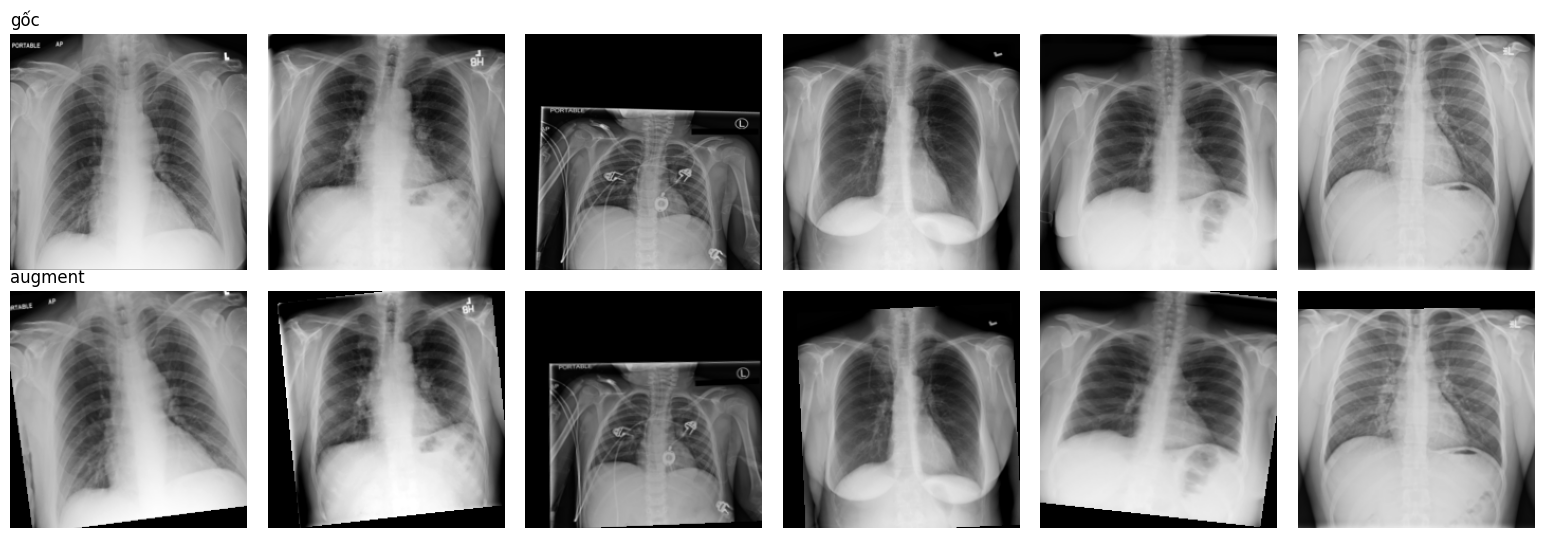

Dải pixel sau augmentation: [0.0, 255.0]


In [14]:
if USE_AUGMENTATION:
    # Kiểm tra bằng mắt: hàng trên = ảnh gốc, hàng dưới = CÙNG các ảnh sau augmentation (vẫn phải là X-quang bình thường, không méo quá mức)
    _n = 6
    _orig_x, _ = next(flow_from_dataframe(base_generator,  train_df.iloc[:_n], _n))
    _aug_x,  _ = next(flow_from_dataframe(train_generator, train_df.iloc[:_n], _n, seed=AUG_SEED))
    fig, axs_ = plt.subplots(2, _n, figsize=(2.6 * _n, 5.4))
    for j in range(_n):
        axs_[0, j].imshow(_orig_x[j].astype('uint8')); axs_[0, j].axis('off')
        axs_[1, j].imshow(_aug_x[j].astype('uint8'));  axs_[1, j].axis('off')
    axs_[0, 0].set_title('gốc', loc='left'); axs_[1, 0].set_title('augment', loc='left')
    plt.tight_layout(); plt.show()
    print(f'Dải pixel sau augmentation: [{_aug_x.min():.1f}, {_aug_x.max():.1f}]')
else:
    print('Augmentation tắt: bỏ qua bước xem ảnh augment.')

## Khối Coordinate Attention (Hou et al., 2021)

In [15]:
class CoordinateAttention(tf.keras.layers.Layer):
    """Coordinate Attention (Hou, Zhou & Feng, 2021), đúng theo Fig. 4 của paper:
    X Avg Pool / Y Avg Pool -> Concat + Conv2d -> BatchNorm + Non-linear -> 2 nhánh Conv2d -> Sigmoid -> Re-weight.
    Input/output: (N, H, W, C) (channels_last). Cùng cấu hình với bản chính thức: reduction=32, mid = max(8, C // reduction), h-swish."""
    def __init__(self, reduction=32, **kwargs):
        super().__init__(**kwargs)
        self.reduction = reduction

    def build(self, input_shape):
        c = int(input_shape[-1])
        mid = max(8, c // self.reduction)
        self.conv1  = tf.keras.layers.Conv2D(mid, 1, name='ca_conv1')
        self.bn1    = tf.keras.layers.BatchNormalization(name='ca_bn1')
        self.conv_h = tf.keras.layers.Conv2D(c, 1, name='ca_conv_h')
        self.conv_w = tf.keras.layers.Conv2D(c, 1, name='ca_conv_w')
        super().build(input_shape)

    @staticmethod
    def _h_swish(x):
        return x * tf.nn.relu6(x + 3.0) / 6.0

    def call(self, x, training=None):
        h = x.shape[1] if x.shape[1] is not None else tf.shape(x)[1]
        w = x.shape[2] if x.shape[2] is not None else tf.shape(x)[2]
        x_h = tf.reduce_mean(x, axis=2, keepdims=True)                 # X Avg Pool: (N,H,1,C)
        x_w = tf.transpose(tf.reduce_mean(x, axis=1, keepdims=True),   # Y Avg Pool: (N,1,W,C) -> (N,W,1,C)
                           [0, 2, 1, 3])
        y = tf.concat([x_h, x_w], axis=1)                              # Concat: (N,H+W,1,C)
        y = self._h_swish(self.bn1(self.conv1(y), training=training))  # Conv2d + BatchNorm + Non-linear
        x_h, x_w = tf.split(y, [h, w], axis=1)
        x_w = tf.transpose(x_w, [0, 2, 1, 3])                          # (N,1,W,mid)
        a_h = tf.sigmoid(self.conv_h(x_h))                             # Conv2d + Sigmoid (nhánh H): (N,H,1,C)
        a_w = tf.sigmoid(self.conv_w(x_w))                             # Conv2d + Sigmoid (nhánh W): (N,1,W,C)
        return x * a_h * a_w                                           # Re-weight

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'reduction': self.reduction})
        return cfg

In [16]:
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.applications.efficientnet import EfficientNetB0

input_shape = (224, 224, 3)
img_input = Input(shape=input_shape)

# Backbone không pooling để còn feature map 4D cho Coordinate Attention
base_model = EfficientNetB0(include_top=False, input_tensor=img_input, input_shape=input_shape,
                            pooling=None, weights='imagenet')   # cần Internet ON để tải trọng số ImageNet
x = base_model.output                                            # (None, 7, 7, 1280) = top_activation
assert tuple(x.shape[1:]) == (7, 7, 1280), x.shape
x = CoordinateAttention(name='coord_att')(x)                     # EfficientNet -> Coordinate Attention
x = GlobalAveragePooling2D(name='avg_pool')(x)                   # thay cho pooling="avg" của backbone
predictions = Dense(len(all_labels), activation="sigmoid", name="predictions")(x)
model = Model(inputs=img_input, outputs=predictions)

_ca_params = model.get_layer('coord_att').count_params()
print(f'EfficientNetB0 + CA: {model.count_params():,} tham số (CA thêm {_ca_params:,}) | số lớp: {len(model.layers)}')
print('Các lớp cuối:', [l.name for l in model.layers[-4:]])
# Keras EfficientNet tự chuẩn hoá bên trong (rescaling, normalization) -> generator KHÔNG được rescale thêm (INPUT_RESCALE=None)
print('Các lớp đầu :', [l.name for l in model.layers[:6]])
assert any(l.name == 'rescaling' for l in model.layers[:4]), "Backbone không có lớp 'rescaling' -> giả định tiền xử lý không còn đúng"
print('INPUT_RESCALE =', INPUT_RESCALE)

I0000 00:00:1792419811.414503      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792419811.418558      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


16705208/16705208 [==============================] - 0s 0us/step
EfficientNetB0 + CA: 4,223,865 tham số (CA thêm 156,360) | số lớp: 241
Các lớp cuối: ['top_activation', 'coord_att', 'avg_pool', 'predictions']
Các lớp đầu : ['input_1', 'rescaling', 'normalization', 'tf.math.multiply', 'stem_conv_pad', 'stem_conv']
INPUT_RESCALE = None


In [17]:
from tensorflow.keras.optimizers import Adam
model.compile(optimizer=Adam(learning_rate=1e-3), loss="binary_crossentropy")

In [18]:
from tensorflow.keras.callbacks import Callback, ReduceLROnPlateau
from sklearn.metrics import roc_auc_score

class MultipleClassAUROC(Callback):
    """Tính mean AUROC trên validation mỗi epoch và lưu trọng số CỦA CHÍNH EPOCH có val AUC cao nhất
    (checkpoint duy nhất). Bản gốc dùng shutil.copy(weights.h5, best_weights.h5): thực chất copy lại mô hình best val_loss."""
    def __init__(self, generator, class_names, best_weights_path):
        super().__init__()
        self.generator = generator
        self.class_names = class_names
        self.best_weights_path = best_weights_path
        self.best_auroc, self.best_epoch = None, 0
        self.val_auc_history = []
        self.per_class_history = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        y_hat = self.model.predict(self.generator, steps=math.ceil(self.generator.n / self.generator.batch_size), verbose=0)
        y = self.generator.labels
        scores = []
        for i in range(len(self.class_names)):
            try:
                scores.append(roc_auc_score(y[:, i], y_hat[:, i]))
            except ValueError:
                scores.append(0)
        mean_auroc = float(np.mean(scores))
        logs['val_auc'] = mean_auroc
        self.val_auc_history.append(mean_auroc)
        self.per_class_history.append([float(s) for s in scores])
        print(f"\n*** epoch#{epoch + 1} | mean val AUC = {mean_auroc:.4f}")
        for i, s in enumerate(scores):
            print(f"  {i+1}. {self.class_names[i]}: {s:.4f}")
        if self.best_auroc is None or mean_auroc > self.best_auroc:
            print(f"-> val_auc tốt nhất: {self.best_auroc} -> {mean_auroc:.4f} | lưu {self.best_weights_path}")
            self.model.save_weights(self.best_weights_path)
            self.best_auroc, self.best_epoch = mean_auroc, epoch + 1

auroc = MultipleClassAUROC(valid_gen, all_labels, P['val_auc'])

rlr = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=2, verbose=1, mode="min", min_lr=1e-8)

class ValAucEarlyStopping(Callback):
    """Dừng khi val_auc không cải thiện (quá min_delta) trong `patience` epoch liên tiếp.
    Phải đứng SAU MultipleClassAUROC trong danh sách callback (để logs['val_auc'] đã có).
    Không khôi phục trọng số: checkpoint val_auc tốt nhất đã được lưu riêng bởi MultipleClassAUROC."""
    def __init__(self, patience=5, min_delta=1e-4):
        super().__init__()
        self.patience, self.min_delta = patience, min_delta
        self.stopped_epoch = None

    def on_train_begin(self, logs=None):
        self.best, self.wait = -np.inf, 0

    def on_epoch_end(self, epoch, logs=None):
        a = (logs or {})['val_auc']
        if a > self.best + self.min_delta:
            self.best, self.wait = a, 0
        else:
            self.wait += 1
        if self.wait >= self.patience:
            self.stopped_epoch = epoch + 1
            self.model.stop_training = True
            print(f"\n[EarlyStopping] val_auc không cải thiện {self.patience} epoch liên tiếp -> dừng ở epoch {epoch + 1}")

es = ValAucEarlyStopping(ES_PATIENCE, ES_MIN_DELTA_AUC)
callbacks = [rlr, auroc] + ([es] if USE_EARLY_STOP else [])
print('Callbacks:', [type(c).__name__ for c in callbacks])

Callbacks: ['ReduceLROnPlateau', 'MultipleClassAUROC', 'ValAucEarlyStopping']


In [19]:
# steps_per_epoch/validation_steps = ceil(n/batch) đúng bằng số batch mà vòng lặp gốc chạy.
fit_history = model.fit(
    train_gen,
    steps_per_epoch=math.ceil(train_gen.n / train_gen.batch_size),
    epochs=EPOCHS,
    validation_data=valid_gen,
    validation_steps=math.ceil(valid_gen.n / valid_gen.batch_size),
    callbacks=callbacks,
    shuffle=False
)

Epoch 1/20


E0000 00:00:1792419830.233681      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inmodel/block2b_drop/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1792419836.849005      70 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2128/2128 [==============================] - ETA: 0s - loss: 0.1438
*** epoch#1 | mean val AUC = 0.7664
  1. Atelectasis: 0.7910
  2. Cardiomegaly: 0.8928
  3. Consolidation: 0.7522
  4. Edema: 0.8706
  5. Effusion: 0.8786
  6. Emphysema: 0.7617
  7. Fibrosis: 0.7291
  8. Hernia: 0.7135
  9. Infiltration: 0.6670
  10. Mass: 0.7646
  11. Nodule: 0.6805
  12. Pleural_Thickening: 0.7616
  13. Pneumonia: 0.7082
  14. Pneumothorax: 0.7586
-> val_auc tốt nhất: None -> 0.7664 | lưu /kaggle/working/ca/weights_val_auc.h5
2128/2128 [==============================] - 3116s 1s/step - loss: 0.1438 - val_loss: 0.1417 - lr: 0.0010 - val_auc: 0.7664
Epoch 2/20
2128/2128 [==============================] - ETA: 0s - loss: 0.1337
*** epoch#2 | mean val AUC = 0.7883
  1. Atelectasis: 0.8061
  2. Cardiomegaly: 0.8978
  3. Consolidation: 0.7795
  4. Edema: 0.9026
  5. Effusion: 0.8875
  6. Emphysema: 0.8366
  7. Fibrosis: 0.7574
  8. Hernia: 0.7444
  9. Infiltration: 0.6796
  10. Mass: 0.8022
  11. Nodule: 

In [20]:
hist = pd.DataFrame(fit_history.history)
hist['val_auc'] = auroc.val_auc_history
hist.insert(0, 'epoch', np.arange(1, len(hist) + 1))
hist.to_csv(P['history'], index=False)

BEST = {'val_auc': {'epoch': auroc.best_epoch, 'value': float(auroc.best_auroc)}}
print('best val_auc :', BEST['val_auc'])
print(f"Số epoch đã chạy: {len(hist)}/{EPOCHS}" + (f" (early stopping dừng ở epoch {es.stopped_epoch})" if USE_EARLY_STOP and es.stopped_epoch else ''))
hist

best val_auc : {'epoch': 7, 'value': 0.8232366551128675}
Số epoch đã chạy: 12/20 (early stopping dừng ở epoch 12)


,epoch,loss,val_loss,lr,val_auc
0,1,0.143812,0.141708,0.001000,0.766419
1,2,0.133713,0.135886,0.001000,0.788320
2,3,0.129704,0.130226,0.001000,0.799017
3,4,0.127028,0.134088,0.001000,0.799682
4,5,0.124895,0.134211,0.001000,0.800967
5,6,0.118774,0.127133,0.000100,0.821425
6,7,0.116970,0.126493,0.000100,0.823237
7,8,0.115524,0.127075,0.000100,0.822689
8,9,0.114476,0.127864,0.000100,0.822340
9,10,0.112910,0.128338,0.000010,0.822375


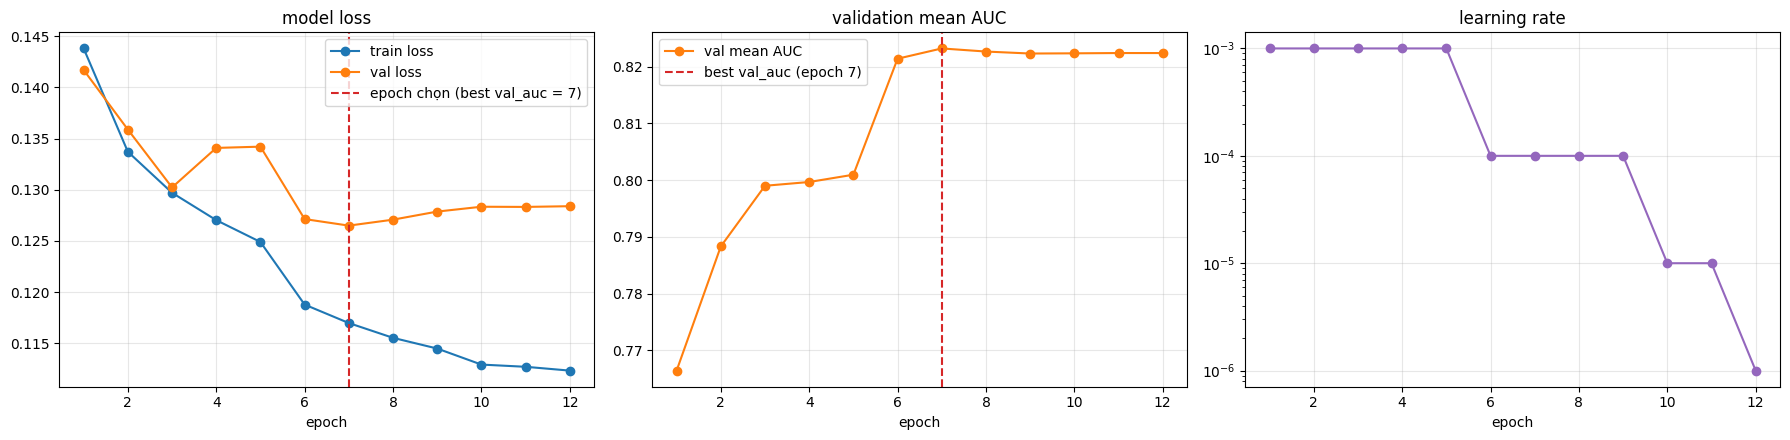

In [21]:
# Biểu đồ huấn luyện
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
ep = hist['epoch']

axs[0].plot(ep, hist['loss'], marker='o', label='train loss')
axs[0].plot(ep, hist['val_loss'], marker='o', label='val loss')
axs[0].axvline(BEST['val_auc']['epoch'], color='tab:red', ls='--', label=f"epoch chọn (best val_auc = {BEST['val_auc']['epoch']})")
axs[0].set_title('model loss'); axs[0].set_xlabel('epoch'); axs[0].legend(); axs[0].grid(alpha=.3)

axs[1].plot(ep, hist['val_auc'], marker='o', color='tab:orange', label='val mean AUC')
axs[1].axvline(BEST['val_auc']['epoch'], color='tab:red', ls='--', label=f"best val_auc (epoch {BEST['val_auc']['epoch']})")
axs[1].set_title('validation mean AUC'); axs[1].set_xlabel('epoch'); axs[1].legend(); axs[1].grid(alpha=.3)

if 'lr' in hist:
    axs[2].semilogy(ep, hist['lr'], marker='o', color='tab:purple')
axs[2].set_title('learning rate'); axs[2].set_xlabel('epoch'); axs[2].grid(alpha=.3)

plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'training_curves.png'), dpi=150)
plt.show()

# Đánh giá trên tập test — ngưỡng tối ưu theo từng bệnh

Không dùng ngưỡng cố định 0.5. Với mỗi bệnh, ngưỡng được chọn trên **tập validation** bằng tiêu chí `THRESHOLD_CRITERION`:
- `'youden'`: cực đại Sensitivity + Specificity − 1 trên đường ROC;
- `'f1'`: cực đại F1 trên đường Precision–Recall.

Sau đó ngưỡng đó được áp **nguyên** lên tập test để tính Accuracy, Precision, Recall, Specificity, F1, MCC (nhãn test không tham gia chọn ngưỡng nên không rò rỉ). AUC-ROC và AUC-PR không phụ thuộc ngưỡng.

**Lưu ý khi đọc kết quả:**
- Mọi chỉ số ở thang 0–1; dòng `Average (macro)` là trung bình cộng của 14 bệnh (cột TP/FP/TN/FN/Support là tổng).
- Với ngưỡng 0.5, mô hình thường dự đoán gần như toàn âm tính ở các bệnh hiếm, nên Accuracy rất cao nhờ lớp âm chiếm đa số. Ngưỡng tối ưu đánh đổi bớt Accuracy để tăng Recall, vì vậy Accuracy sẽ **thấp hơn** so với khi dùng 0.5 mà mô hình không hề kém đi. Hãy đọc cùng Recall, Specificity, F1 và MCC.

In [22]:
from sklearn.metrics import (roc_curve, precision_recall_curve, roc_auc_score, average_precision_score,
                             matthews_corrcoef)
import json

RESULTS = {}
RATIO_COLS = ['AUC-ROC', 'AUC-PR', 'Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'MCC']

def optimal_threshold(y, p, criterion=THRESHOLD_CRITERION):
    """Ngưỡng tối ưu của MỘT bệnh, tính trên validation. Dự đoán dương khi p >= ngưỡng."""
    if y.sum() == 0 or y.sum() == len(y):
        return 0.5                                                   # validation thiếu một lớp -> không chọn được
    if criterion == 'youden':
        fpr, tpr, thr = roc_curve(y, p)
        k = int(np.argmax(tpr - fpr)); t = thr[k]
    elif criterion == 'f1':
        pr, rc, thr = precision_recall_curve(y, p)
        f1 = 2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12)
        k = int(np.argmax(f1)); t = thr[k]
    else:
        raise ValueError(f"THRESHOLD_CRITERION phải là 'youden' hoặc 'f1', nhận {criterion!r}")
    return float(t) if np.isfinite(t) else 0.5

def class_metrics(y, p, thr):
    """Các chỉ số của MỘT bệnh trên test, tại ngưỡng thr (chọn từ validation)."""
    yb = (p >= thr).astype(int)
    tp = int(((yb == 1) & (y == 1)).sum()); fp = int(((yb == 1) & (y == 0)).sum())
    tn = int(((yb == 0) & (y == 0)).sum()); fn = int(((yb == 0) & (y == 1)).sum())
    d = lambda a, b: a / b if b else 0.0
    return {'Threshold': thr, 'Support': int(y.sum()), 'Prevalence': float(y.mean()),
            'AUC-ROC': float(roc_auc_score(y, p)) if 0 < y.sum() < len(y) else float('nan'),
            'AUC-PR': float(average_precision_score(y, p)) if y.sum() > 0 else float('nan'),
            'Accuracy': d(tp + tn, len(y)), 'Precision': d(tp, tp + fp), 'Recall': d(tp, tp + fn),
            'Specificity': d(tn, tn + fp), 'F1': d(2 * tp, 2 * tp + fp + fn), 'MCC': float(matthews_corrcoef(y, yb)),
            'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn}

def evaluate_checkpoint(tag, weights_path):
    """Nạp checkpoint; chọn ngưỡng từng bệnh trên validation; đánh giá trên test với các ngưỡng đó."""
    assert os.path.isfile(weights_path), f'Thiếu {weights_path}'
    model.load_weights(weights_path)
    valid_gen.reset(); test_gen.reset()
    pred_val  = model.predict(valid_gen, steps=math.ceil(valid_gen.n / valid_gen.batch_size), verbose=0)
    pred_test = model.predict(test_gen,  steps=math.ceil(test_gen.n / test_gen.batch_size), verbose=1)
    y_val, y_test = np.asarray(valid_gen.labels).astype(int), np.asarray(test_gen.labels).astype(int)
    assert y_val.shape == pred_val.shape and y_test.shape == pred_test.shape, (y_val.shape, pred_val.shape, y_test.shape, pred_test.shape)

    thr = [optimal_threshold(y_val[:, i], pred_val[:, i]) for i in range(len(all_labels))]
    table = pd.DataFrame([class_metrics(y_test[:, i], pred_test[:, i], thr[i]) for i in range(len(all_labels))], index=all_labels)
    table.index.name = 'Pathology'
    avg = {c: float(table[c].mean()) for c in RATIO_COLS}                            # trung bình macro (bỏ qua NaN)
    avg.update({c: int(table[c].sum()) for c in ('Support', 'TP', 'FP', 'TN', 'FN')})
    table.loc['Average (macro)'] = pd.Series(avg)
    for c in ('Support', 'TP', 'FP', 'TN', 'FN'):
        table[c] = table[c].astype(int)                                              # giữ số nguyên sau khi thêm dòng trung bình

    np.save(os.path.join(OUT_DIR, f'pred_val_{tag}.npy'), pred_val)
    np.save(os.path.join(OUT_DIR, f'pred_test_{tag}.npy'), pred_test)
    json.dump({'criterion': THRESHOLD_CRITERION, 'thresholds': dict(zip(all_labels, thr))},
              open(os.path.join(OUT_DIR, f'thresholds_{tag}.json'), 'w'), indent=1, ensure_ascii=False)
    return {'tag': tag, 'pred_val': pred_val, 'pred_test': pred_test, 'y_val': y_val, 'y_true': y_test, 'thr': thr, 'table': table}

def report(tag, label, res, info):
    print(f"##### {label}: {info} | tiêu chí ngưỡng: {THRESHOLD_CRITERION} (chọn trên validation)")
    t = res['table']
    display(t.round(4))
    t.round(4).to_csv(os.path.join(OUT_DIR, f'metrics_per_class_{tag}.csv'))

    # ---- Biểu đồ cột: AUC-ROC, Recall, Precision, F1 theo từng bệnh (ngưỡng tối ưu) ----
    cols, colors = ['AUC-ROC', 'Recall', 'Precision', 'F1'], ['#e6550d', '#3182bd', '#31a354', '#756bb1']
    names = list(t.index); x = np.arange(len(names)); w = 0.2
    fig, ax = plt.subplots(figsize=(16, 5.5))
    for j, (c, col) in enumerate(zip(cols, colors)):
        ax.bar(x + (j - 1.5) * w, t[c].values, w, color=col, label=c)
    ax.axvline(len(names) - 1.5, color='gray', ls=':', lw=1)
    ax.set_xticks(x); ax.set_xticklabels([n.replace('_', ' ') for n in names], rotation=35, ha='right')
    ax.set_ylim(0, 1.15); ax.set_ylabel('giá trị (0-1)')
    ax.set_title(f'Chỉ số từng bệnh tại ngưỡng tối ưu ({label}, test chính thức NIH)')
    ax.legend(ncol=4, frameon=False, loc='upper center'); ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)
    plt.tight_layout(); fig.savefig(os.path.join(OUT_DIR, f'metrics_bar_{tag}.png'), dpi=150); plt.show()

    # ---- ROC các bệnh, đánh dấu điểm làm việc tại ngưỡng tối ưu ----
    fig, c_ax = plt.subplots(1, 1, figsize=(9, 9))
    for idx, c_label in enumerate(all_labels):
        fpr, tpr, _ = roc_curve(res['y_true'][:, idx], res['pred_test'][:, idx])
        line, = c_ax.plot(fpr, tpr, label='%s (AUC:%0.2f)' % (c_label, t.loc[c_label, 'AUC-ROC']))
        r = t.loc[c_label]
        c_ax.scatter([r['FP'] / max(r['FP'] + r['TN'], 1)], [r['Recall']], color=line.get_color(), marker='o', s=35, edgecolor='k', zorder=3)
    c_ax.plot([0, 1], [0, 1], 'k:', lw=1)
    c_ax.legend(fontsize=8); c_ax.set_xlabel('False Positive Rate'); c_ax.set_ylabel('True Positive Rate')
    c_ax.set_title(f'ROC trên test - {label} (chấm = ngưỡng tối ưu của từng bệnh)')
    fig.savefig(os.path.join(OUT_DIR, f'roc_test_{tag}.png')); plt.show()

    # ---- Ví dụ dự đoán (16 ảnh đầu của tập test), dự đoán dương theo ngưỡng của từng bệnh ----
    test_gen.reset()
    test_x, test_y = next(test_gen)
    pred_y, thr = res['pred_test'], res['thr']
    sickest_idx = np.argsort(np.sum(test_y, 1) < 1)
    fig, m_axs = plt.subplots(4, 4, figsize=(16, 16))
    fig.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)
    for idx, c_ax in zip(sickest_idx, m_axs.flatten()):
        c_ax.imshow(test_x[idx, :, :, 0], cmap='bone')
        stat_str = [n[:4] for n, s in zip(all_labels, test_y[idx]) if s > 0.5]
        pred_str = [f'{n[:4]}:{p*100:.1f}%' for n, s, p, th in zip(all_labels, test_y[idx], pred_y[idx], thr) if (s > 0.5) or (p >= th)]
        c_ax.set_title(f'Index {idx}, Labels: ' + ', '.join(stat_str) + '\n Pred (>= ngưỡng bệnh): ' + ', '.join(pred_str))
        c_ax.axis('off')
    fig.savefig(os.path.join(OUT_DIR, f'pred_samples_{tag}.png')); plt.show()

## Đánh giá checkpoint `val_auc` (`weights_val_auc.h5`)
Trọng số của epoch có mean AUC validation cao nhất (chọn trên validation, báo cáo trên test nên không rò rỉ).

776/776 [==============================] - 549s 708ms/step
##### checkpoint val_auc: epoch 7, val_auc=0.8232 | tiêu chí ngưỡng: f1 (chọn trên validation)


,Threshold,Support,Prevalence,AUC-ROC,AUC-PR,Accuracy,Precision,Recall,Specificity,F1,MCC,TP,FP,TN,FN
Pathology,,,,,,,,,,,,,,,
Atelectasis,0.1731,3009,0.1213,0.7735,0.3281,0.7862,0.2958,0.5523,0.8185,0.3853,0.2893,1662,3956,17839,1347
Cardiomegaly,0.2101,889,0.0358,0.8952,0.3291,0.9546,0.3815,0.4274,0.9742,0.4032,0.3804,380,616,23299,509
Consolidation,0.1140,1573,0.0634,0.7524,0.1549,0.8019,0.1545,0.4749,0.8240,0.2331,0.1839,747,4088,19143,826
Edema,0.1268,779,0.0314,0.8447,0.1482,0.9095,0.1538,0.4185,0.9254,0.2250,0.2146,326,1793,22232,453
Effusion,0.3635,4286,0.1728,0.8267,0.4950,0.8130,0.4668,0.5777,0.8622,0.5164,0.4056,2476,2828,17690,1810
Emphysema,0.1429,952,0.0384,0.8984,0.3927,0.9493,0.3844,0.5326,0.9660,0.4465,0.4268,507,812,23040,445
Fibrosis,0.1740,341,0.0137,0.8196,0.0840,0.9821,0.1905,0.0938,0.9944,0.1257,0.1253,32,136,24327,309
Hernia,0.0059,60,0.0024,0.8076,0.0128,0.9811,0.0188,0.1333,0.9831,0.0330,0.0441,8,417,24327,52
Infiltration,0.2978,5746,0.2317,0.6757,0.3693,0.6145,0.3328,0.6610,0.6005,0.4427,0.2213,3798,7614,11444,1948


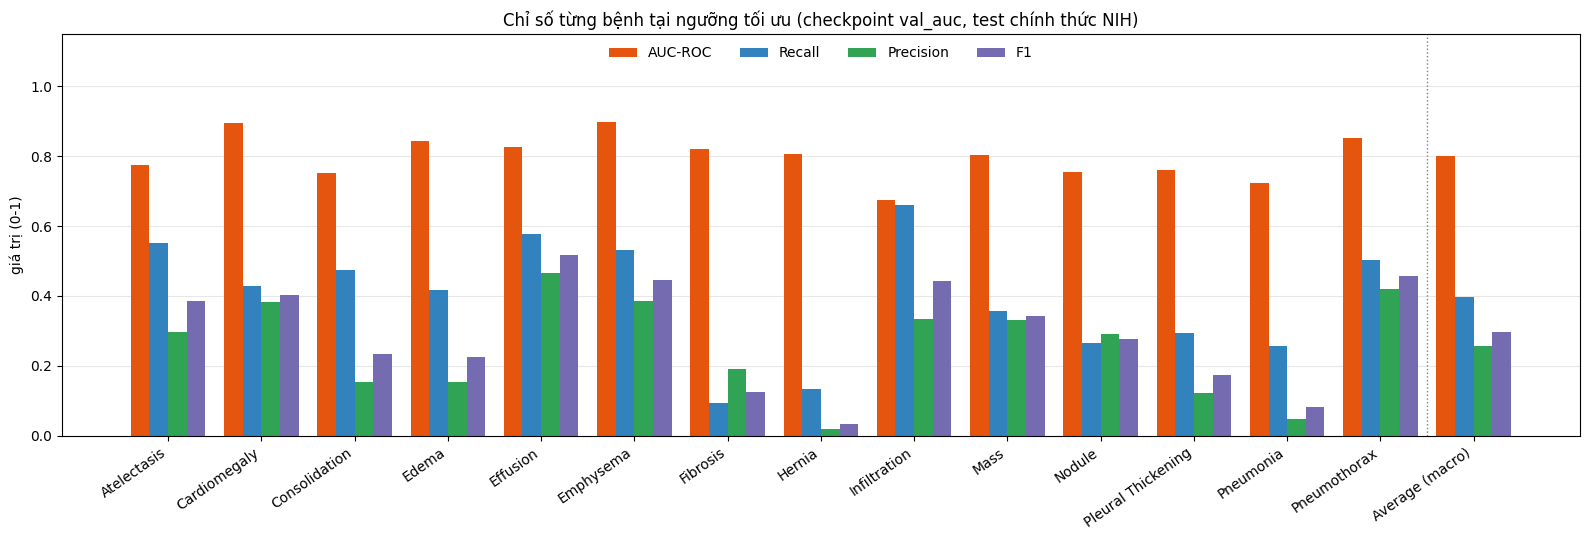

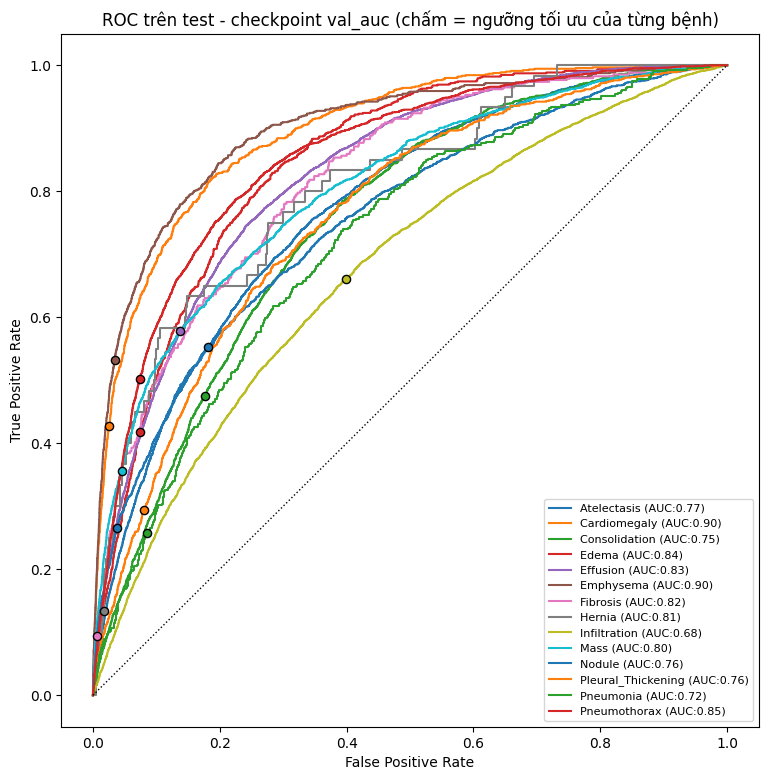

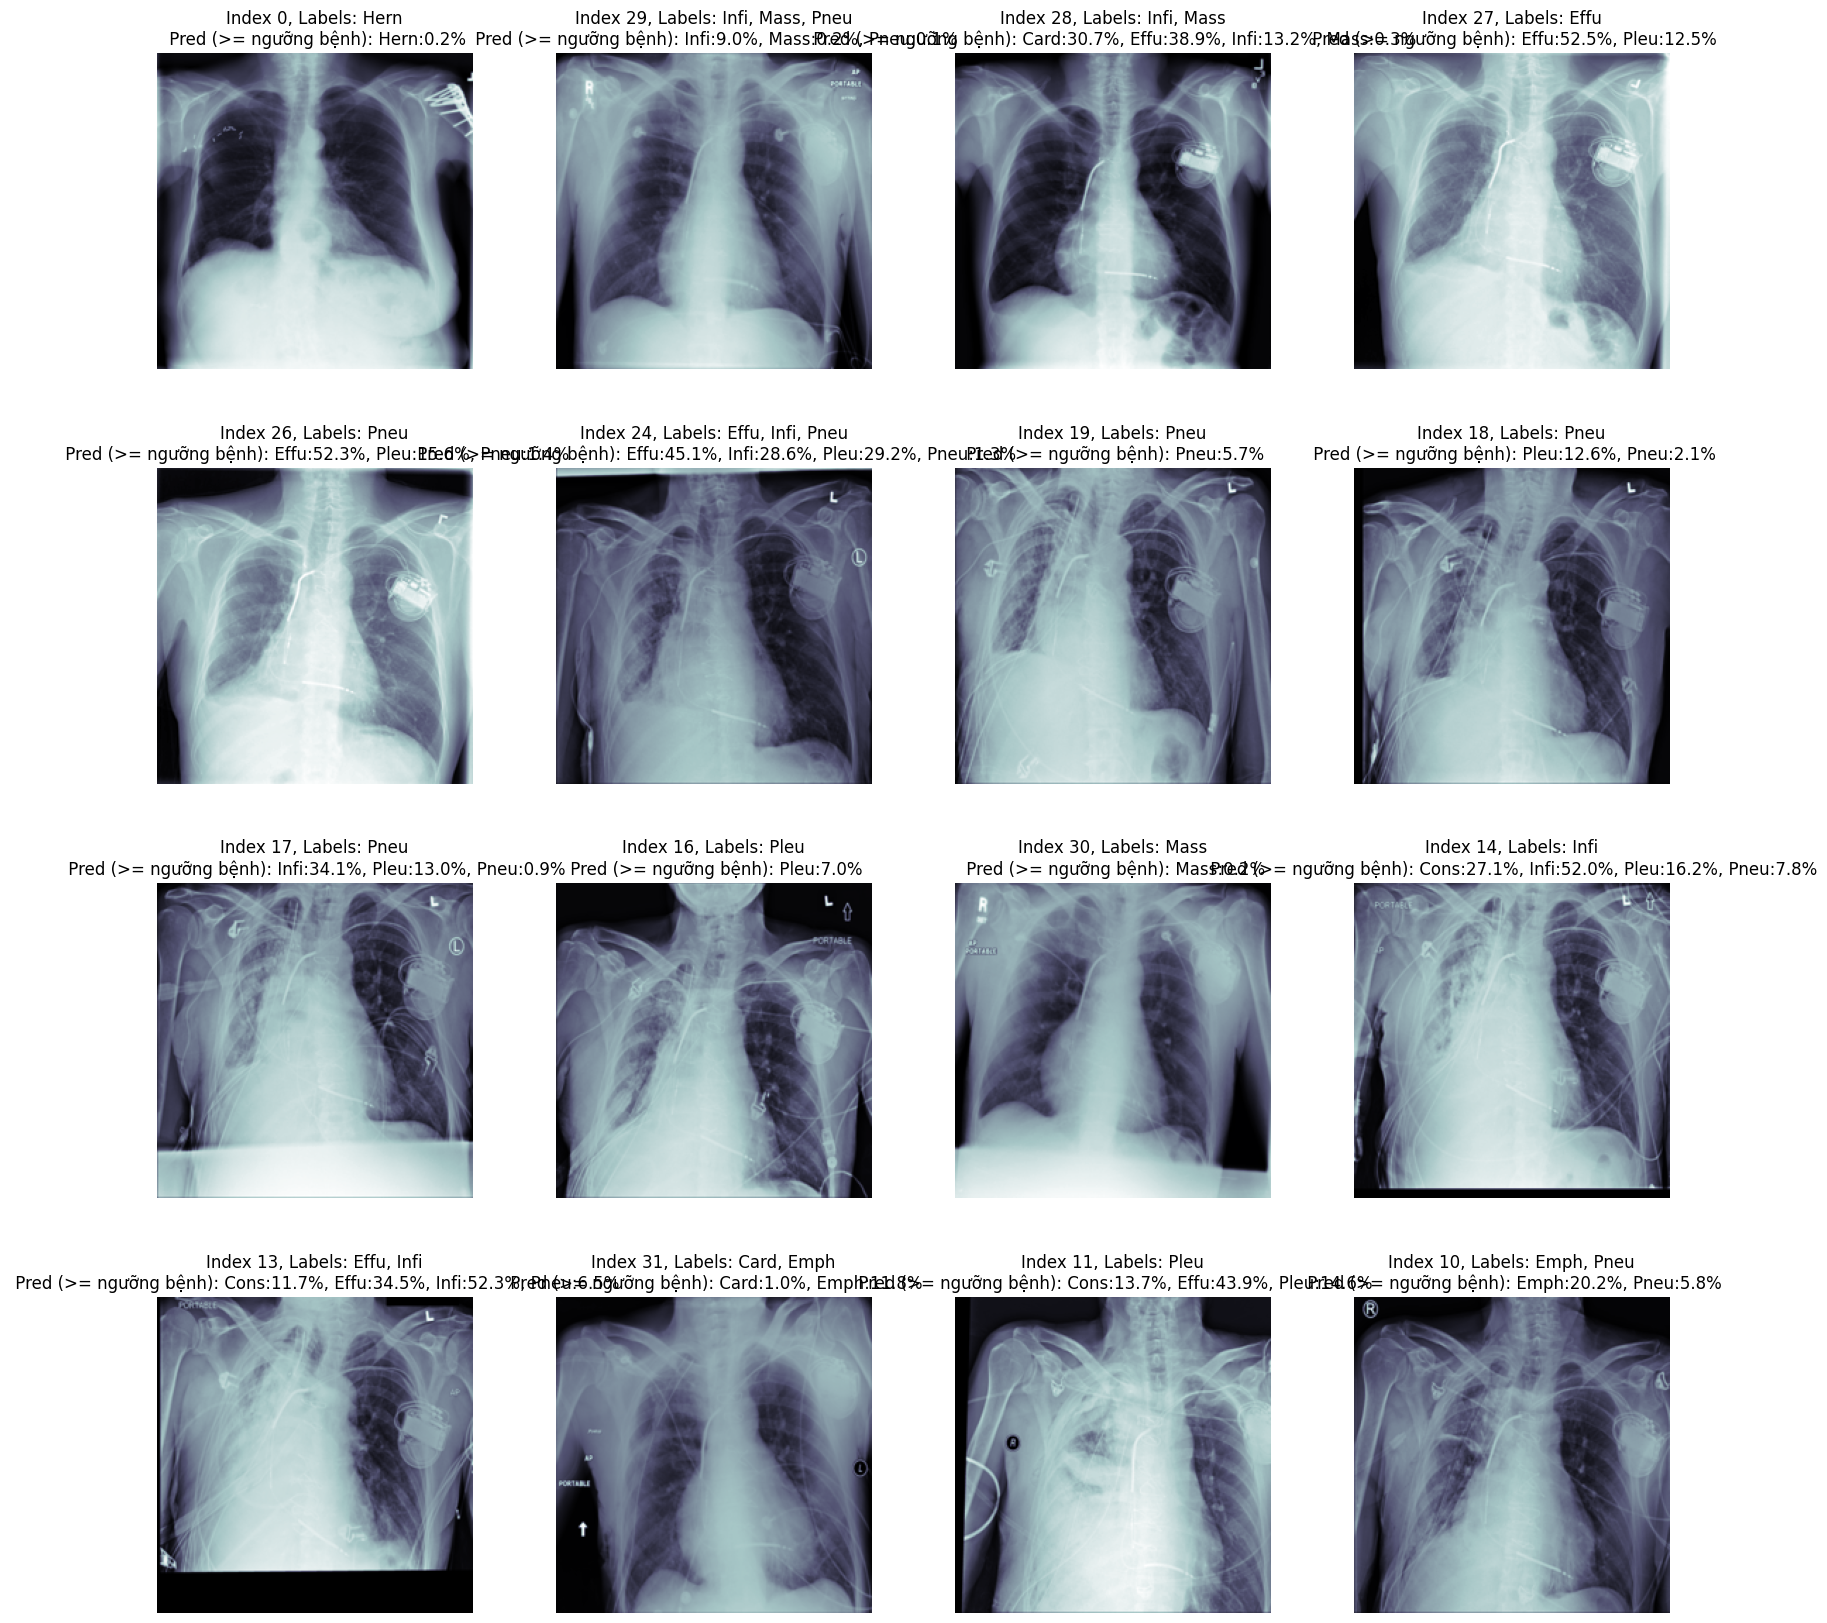

In [23]:
RESULTS['val_auc'] = evaluate_checkpoint('val_auc', P['val_auc'])
report('val_auc', 'checkpoint val_auc', RESULTS['val_auc'],
       f"epoch {BEST['val_auc']['epoch']}, val_auc={BEST['val_auc']['value']:.4f}")

## TỔNG HỢP

In [24]:
summary = pd.DataFrame([{'Checkpoint': 'val_auc', 'Epoch': BEST['val_auc']['epoch'],
                         'Val metric': f"val_auc={BEST['val_auc']['value']:.4f}",
                         'Test avg AUC-ROC': round(float(RESULTS['val_auc']['table'].loc['Average (macro)', 'AUC-ROC']), 4)}])
display(summary)
summary.to_csv(os.path.join(OUT_DIR, 'summary.csv'), index=False)

per_class_auc = pd.DataFrame({'Pathology': list(all_labels),
                              'AUC-ROC': np.round(RESULTS['val_auc']['table'].loc[all_labels, 'AUC-ROC'].values, 4)})
display(per_class_auc)
per_class_auc.to_csv(os.path.join(OUT_DIR, 'auc_per_class.csv'), index=False)

thr_table = pd.DataFrame({'Pathology': list(all_labels),
                          f'Ngưỡng ({THRESHOLD_CRITERION})': np.round(RESULTS['val_auc']['thr'], 4)})
display(thr_table)
thr_table.to_csv(os.path.join(OUT_DIR, 'thresholds.csv'), index=False)
print('Số mẫu test:', len(test_gen.labels), '| Lưu ý: bệnh ít mẫu (Hernia, Pneumonia...) có sai số lớn, nên ưu tiên so sánh trung bình.')

,Checkpoint,Epoch,Val metric,Test avg AUC-ROC
0,val_auc,7,val_auc=0.8232,0.7992


,Pathology,AUC-ROC
0,Atelectasis,0.7735
1,Cardiomegaly,0.8952
2,Consolidation,0.7524
3,Edema,0.8447
4,Effusion,0.8267
5,Emphysema,0.8984
6,Fibrosis,0.8196
7,Hernia,0.8076
8,Infiltration,0.6757
9,Mass,0.8043


,Pathology,Ngưỡng (f1)
0,Atelectasis,0.1731
1,Cardiomegaly,0.2101
2,Consolidation,0.1140
3,Edema,0.1268
4,Effusion,0.3635
5,Emphysema,0.1429
6,Fibrosis,0.1740
7,Hernia,0.0059
8,Infiltration,0.2978
9,Mass,0.2176


Số mẫu test: 24804 | Lưu ý: bệnh ít mẫu (Hernia, Pneumonia...) có sai số lớn, nên ưu tiên so sánh trung bình.


In [25]:
# Các chỉ số tổng hợp trên tập test, mỗi bệnh dùng ngưỡng tối ưu riêng (chọn trên validation)
def overall_metrics(res):
    t = res['table']; a = t.loc['Average (macro)']
    tp, fp, fn = int(a['TP']), int(a['FP']), int(a['FN'])
    return {'AUC-ROC (macro)':   float(a['AUC-ROC']),
            'AUC-PR (macro)':    float(a['AUC-PR']),
            'Accuracy (macro)':  float(a['Accuracy']),
            'Precision (macro)': float(a['Precision']),
            'Recall (macro)':    float(a['Recall']),
            'Specificity (macro)': float(a['Specificity']),
            'F1-Macro':          float(a['F1']),
            'F1-Micro':          float(2 * tp / (2 * tp + fp + fn)) if (2 * tp + fp + fn) else 0.0,
            'MCC (macro)':       float(a['MCC'])}

metrics_df = pd.DataFrame({'Benchmark (ckpt val_auc)': overall_metrics(RESULTS['val_auc'])})
display(metrics_df.round(4))
metrics_df.round(4).to_csv(os.path.join(OUT_DIR, 'overall_metrics.csv'))

,Benchmark (ckpt val_auc)
AUC-ROC (macro),0.7992
AUC-PR (macro),0.2392
Accuracy (macro),0.8800
Precision (macro),0.2565
Recall (macro),0.3962
Specificity (macro),0.9018
F1-Macro,0.2959
F1-Micro,0.3730
MCC (macro),0.2459


## SO SÁNH CÁC BƯỚC CẢI TIẾN

,Benchmark (B0),B0 + CA (1/255),B0 + CA (noresc),B0 + CA (noresc + aug + ES),Δ vs noresc,Δ vs benchmark
AUC-ROC (macro),0.7735,0.7748,0.7841,0.7992,0.0151,0.0257
AUC-PR (macro),0.2127,0.2105,0.2177,0.2392,0.0215,0.0265
Accuracy (macro),0.8855,0.8727,0.8736,0.8800,0.0064,-0.0055
Precision (macro),0.2502,0.2250,0.2275,0.2565,0.0290,0.0063
Recall (macro),0.3251,0.3642,0.3763,0.3962,0.0199,0.0711
Specificity (macro),0.9089,0.8940,0.8950,0.9018,0.0068,-0.0071
F1-Macro,0.2678,0.2679,0.2718,0.2959,0.0241,0.0281
F1-Micro,0.3685,0.3530,0.3568,0.3730,0.0162,0.0045
MCC (macro),0.2119,0.2124,0.2185,0.2459,0.0274,0.0340


,Benchmark (B0),B0 + CA (1/255),B0 + CA (noresc),B0 + CA (noresc + aug + ES),Δ vs noresc,Δ vs benchmark
Atelectasis,0.7497,0.7502,0.7603,0.7735,0.0132,0.0238
Cardiomegaly,0.8694,0.8549,0.8685,0.8952,0.0267,0.0258
Consolidation,0.7225,0.7267,0.7335,0.7524,0.0189,0.0299
Edema,0.8158,0.8072,0.8333,0.8447,0.0114,0.0289
Effusion,0.8088,0.8085,0.8123,0.8267,0.0144,0.0179
Emphysema,0.8654,0.8588,0.8677,0.8984,0.0307,0.0330
Fibrosis,0.7761,0.7617,0.7922,0.8196,0.0274,0.0435
Hernia,0.8257,0.8359,0.8254,0.8076,-0.0178,-0.0181
Infiltration,0.6716,0.6751,0.6820,0.6757,-0.0063,0.0041
Mass,0.7746,0.7818,0.7873,0.8043,0.0170,0.0297


Bản này cao hơn bản noresc ở 12/14 bệnh | Δ AUC trung bình = +0.0151
Bản này cao hơn benchmark ở 13/14 bệnh | Δ AUC trung bình = +0.0257
Lưu ý: kết quả của MỘT seed; chênh lệch nhỏ (cỡ ±0.01 AUC trung bình) chưa đủ để kết luận. Xem thêm khoảng cách train loss - val loss ở đường cong huấn luyện.


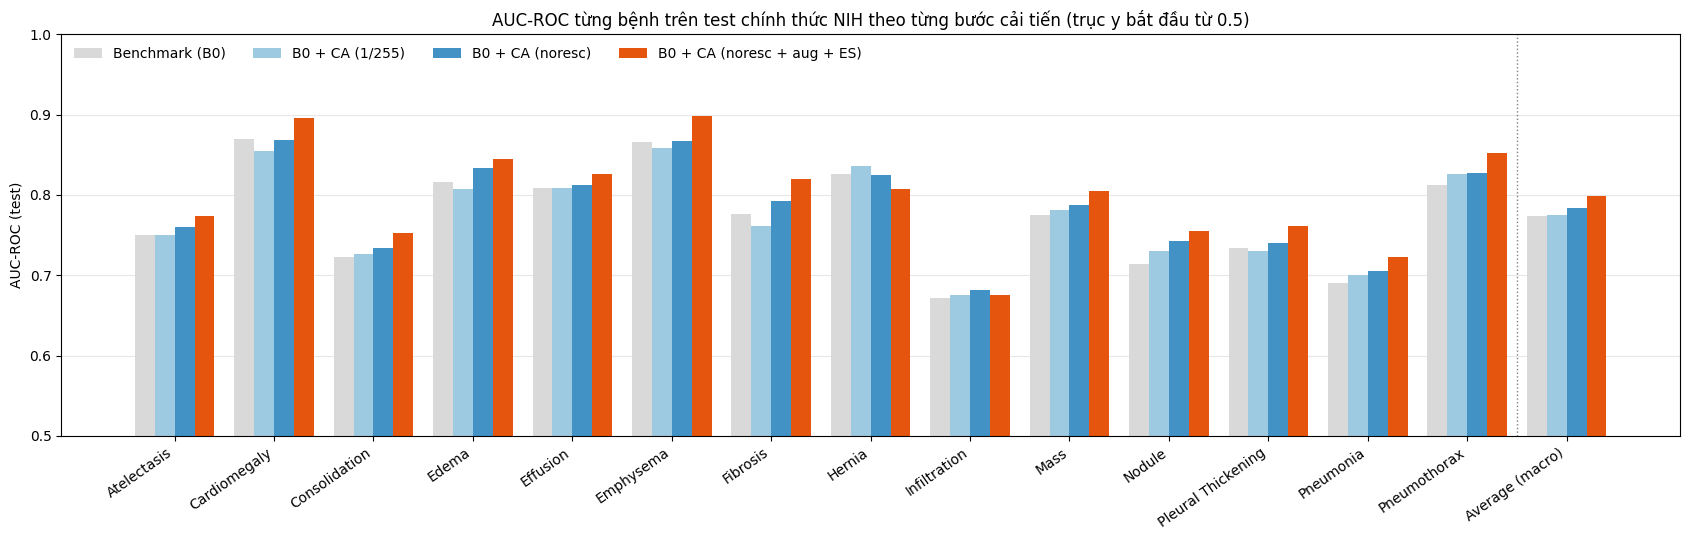

In [26]:
# ---- Số liệu các bản trước (cùng split/seed/pipeline/ngưỡng F1; checkpoint val_auc) ----
# TODO: khi có kết quả mới (có seed), dán số vào 6 dict dưới đây (lấy từ auc_per_class.csv và overall_metrics.csv của từng notebook).
# BENCH_* và CA_* là số bạn đã chạy (có seed). NORESC_* đang là số giữ chỗ (copy của CA) cho tới khi có kết quả noresc.
BENCH_AUC = {'Atelectasis': 0.7497, 'Cardiomegaly': 0.8694, 'Consolidation': 0.7225, 'Edema': 0.8158,
             'Effusion': 0.8088, 'Emphysema': 0.8654, 'Fibrosis': 0.7761, 'Hernia': 0.8257,
             'Infiltration': 0.6716, 'Mass': 0.7746, 'Nodule': 0.7144, 'Pleural_Thickening': 0.7336,
             'Pneumonia': 0.6898, 'Pneumothorax': 0.8119}
BENCH_OVERALL = {'AUC-ROC (macro)': 0.7735, 'AUC-PR (macro)': 0.2127, 'Accuracy (macro)': 0.8855,
                 'Precision (macro)': 0.2502, 'Recall (macro)': 0.3251, 'Specificity (macro)': 0.9089,
                 'F1-Macro': 0.2678, 'F1-Micro': 0.3685, 'MCC (macro)': 0.2119}
CA_AUC = {'Atelectasis': 0.7502, 'Cardiomegaly': 0.8549, 'Consolidation': 0.7267, 'Edema': 0.8072,
          'Effusion': 0.8085, 'Emphysema': 0.8588, 'Fibrosis': 0.7617, 'Hernia': 0.8359,
          'Infiltration': 0.6751, 'Mass': 0.7818, 'Nodule': 0.7297, 'Pleural_Thickening': 0.7299,
          'Pneumonia': 0.7005, 'Pneumothorax': 0.8266}
CA_OVERALL = {'AUC-ROC (macro)': 0.7748, 'AUC-PR (macro)': 0.2105, 'Accuracy (macro)': 0.8727,
              'Precision (macro)': 0.2250, 'Recall (macro)': 0.3642, 'Specificity (macro)': 0.8940,
              'F1-Macro': 0.2679, 'F1-Micro': 0.3530, 'MCC (macro)': 0.2124}
NORESC_AUC = {'Atelectasis': 0.7603, 'Cardiomegaly': 0.8685, 'Consolidation': 0.7335, 'Edema': 0.8333,
          'Effusion': 0.8123, 'Emphysema': 0.8677, 'Fibrosis': 0.7922, 'Hernia': 0.8254,
          'Infiltration': 0.6820, 'Mass': 0.7873, 'Nodule': 0.7432, 'Pleural_Thickening': 0.7399,
          'Pneumonia': 0.7052, 'Pneumothorax': 0.8273}
NORESC_OVERALL = {'AUC-ROC (macro)': 0.7841, 'AUC-PR (macro)': 0.2177, 'Accuracy (macro)': 0.8736,
              'Precision (macro)': 0.2275, 'Recall (macro)': 0.3763, 'Specificity (macro)': 0.8950,
              'F1-Macro': 0.2718, 'F1-Micro': 0.3568, 'MCC (macro)': 0.2185}
L_BENCH, L_CA, L_NORESC = 'Benchmark (B0)', 'B0 + CA (1/255)', 'B0 + CA (noresc)'
L_THIS = 'B0 + CA (noresc + aug + ES)'

def overall_metrics(res):
    t = res['table']; a = t.loc['Average (macro)']
    tp, fp, fn = int(a['TP']), int(a['FP']), int(a['FN'])
    return {'AUC-ROC (macro)': float(a['AUC-ROC']), 'AUC-PR (macro)': float(a['AUC-PR']),
            'Accuracy (macro)': float(a['Accuracy']), 'Precision (macro)': float(a['Precision']),
            'Recall (macro)': float(a['Recall']), 'Specificity (macro)': float(a['Specificity']),
            'F1-Macro': float(a['F1']), 'F1-Micro': float(2 * tp / (2 * tp + fp + fn)) if (2 * tp + fp + fn) else 0.0,
            'MCC (macro)': float(a['MCC'])}

# 1) Bảng chỉ số tổng hợp
cmp_overall = pd.DataFrame({L_BENCH: BENCH_OVERALL, L_CA: CA_OVERALL, L_NORESC: NORESC_OVERALL,
                            L_THIS: overall_metrics(RESULTS['val_auc'])})
cmp_overall['Δ vs noresc'] = cmp_overall[L_THIS] - cmp_overall[L_NORESC]
cmp_overall['Δ vs benchmark'] = cmp_overall[L_THIS] - cmp_overall[L_BENCH]
display(cmp_overall.round(4))
cmp_overall.round(4).to_csv(os.path.join(OUT_DIR, 'compare_overall.csv'))

# 2) Bảng AUC-ROC từng bệnh
cmp_auc = pd.DataFrame({L_BENCH: pd.Series(BENCH_AUC), L_CA: pd.Series(CA_AUC), L_NORESC: pd.Series(NORESC_AUC),
                        L_THIS: RESULTS['val_auc']['table'].loc[all_labels, 'AUC-ROC']}).loc[all_labels]
cmp_auc['Δ vs noresc'] = cmp_auc[L_THIS] - cmp_auc[L_NORESC]
cmp_auc['Δ vs benchmark'] = cmp_auc[L_THIS] - cmp_auc[L_BENCH]
cmp_auc.loc['Average (macro)'] = cmp_auc.mean()
display(cmp_auc.round(4))
cmp_auc.round(4).to_csv(os.path.join(OUT_DIR, 'compare_auc_per_class.csv'))
for col, name in (('Δ vs noresc', 'bản noresc'), ('Δ vs benchmark', 'benchmark')):
    print(f"Bản này cao hơn {name} ở {int((cmp_auc.loc[all_labels, col] > 0).sum())}/{len(all_labels)} bệnh | Δ AUC trung bình = {cmp_auc.loc['Average (macro)', col]:+.4f}")
print("Lưu ý: kết quả của MỘT seed; chênh lệch nhỏ (cỡ ±0.01 AUC trung bình) chưa đủ để kết luận. Xem thêm khoảng cách train loss - val loss ở đường cong huấn luyện.")

# 3) Biểu đồ so sánh AUC-ROC từng bệnh theo thứ tự cải tiến (giá trị chính xác xem ở bảng trên)
names = list(cmp_auc.index); x = np.arange(len(names)); w = 0.2
fig, ax = plt.subplots(figsize=(17, 5.5))
for j, (lab, col) in enumerate(((L_BENCH, '#d9d9d9'), (L_CA, '#9ecae1'), (L_NORESC, '#4292c6'), (L_THIS, '#e6550d'))):
    ax.bar(x + (j - 1.5) * w, cmp_auc[lab].values, w, color=col, label=lab)
ax.axvline(len(names) - 1.5, color='gray', ls=':', lw=1)
ax.set_xticks(x); ax.set_xticklabels([n.replace('_', ' ') for n in names], rotation=35, ha='right')
ax.set_ylim(0.5, 1.0); ax.set_ylabel('AUC-ROC (test)')
ax.set_title('AUC-ROC từng bệnh trên test chính thức NIH theo từng bước cải tiến (trục y bắt đầu từ 0.5)')
ax.legend(frameon=False, loc='upper left', ncol=4); ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)
plt.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'auc_roc_compare.png'), dpi=150); plt.show()